# SQL para decisões de restaurante

Estudo independente com dados sintéticos e assistência de IA. Células executadas; sem dados privados, rede ou modelos binários de terceiros. A explicação aprofundada está em `docs/EXPLICACAO_COMPLETA.md`. Reexecute em uma sessão nova.

In [1]:
from pathlib import Path
import sys, json, contextlib, io
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.pipeline import *
from IPython.display import display, Image
print('Seed:', SEED)

Seed: 20261111


## Executar a implementação

O notebook importa as mesmas funções usadas no pipeline e no painel. O stdout completo pode ser consultado pela execução no terminal; aqui mostramos os indicadores relevantes.

In [2]:
buffer = io.StringIO()
with contextlib.redirect_stdout(buffer):
    result = run()
print(json.dumps(result['environment'], indent=2))

{
  "python": "3.10.12",
  "numpy": "2.2.6",
  "pandas": "2.3.3",
  "matplotlib": "3.10.9",
  "seed": 20261111
}


## Granularidade e conciliação

Pedidos são uma linha por pedido; itens são uma linha por produto/pedido. Pré-agregamos itens antes do JOIN. O exemplo padrão tem 500 pedidos e R$44.592,00. A tabela deve conciliar pedido a pedido, não só no agregado.

In [3]:
con = create_connection()
load(con)
reconciliation = query(con, '02_reconcile.sql')
assert (reconciliation.total_cents == reconciliation.line_total_cents).all()
print('Pedidos reconciliados:', len(reconciliation))
display(reconciliation.head())

Pedidos reconciliados: 500


,order_id,total_cents,line_total_cents
0,1,8400,8400
1,2,12400,12400
2,3,2100,2100
3,4,14400,14400
4,5,2400,2400


## O contraexemplo do JOIN

Somar o total do pedido depois de expandir seus itens conta o pedido mais de uma vez. Não é um pequeno erro de arredondamento.

In [4]:
correct = con.execute('SELECT SUM(total_cents) FROM orders').fetchone()[0]
wrong = con.execute('SELECT SUM(o.total_cents) FROM orders o JOIN order_lines l USING(order_id)').fetchone()[0]
display(pd.DataFrame([{'correct_cents': correct, 'wrong_cents': wrong, 'overcount_cents': wrong-correct}]))
assert wrong > correct

,correct_cents,wrong_cents,overcount_cents
0,4459200,10277500,5818300


## Ranking e janela

A consulta usa CTE e soma sobre janela. Ordenação e desempate são explícitos, antes do limite. Receita maior não demonstra eficiência maior.

In [5]:
print((SQL/'03_restaurants.sql').read_text())
display(query(con, '03_restaurants.sql'))

-- Agrega pedidos antes de calcular participação. Desempate explícito.
WITH revenue AS (SELECT restaurant_id,COUNT(*) AS orders,SUM(total_cents) AS revenue_cents FROM orders GROUP BY restaurant_id)
SELECT *,ROUND(100.0*revenue_cents/SUM(revenue_cents) OVER(),3) AS share_pct,
DENSE_RANK() OVER(ORDER BY revenue_cents DESC) AS revenue_rank
FROM revenue ORDER BY revenue_cents DESC,restaurant_id LIMIT 5;



,restaurant_id,orders,revenue_cents,share_pct,revenue_rank
0,1,120,1024600,22.977,1
1,5,91,933800,20.941,2
2,2,100,854300,19.158,3
3,4,86,827100,18.548,4
4,3,103,819400,18.375,5


## Meses, margem e ticket

A primeira diferença mensal é ausente porque não há mês anterior no recorte. A margem usa custo fictício e não é lucro líquido.

04_monthly.sql


,month,revenue_cents,orders,change_cents
0,2025-01,650700,71,NaN
1,2025-02,759200,87,108500.0
2,2025-03,772000,92,12800.0
3,2025-04,605600,70,-166400.0
4,2025-05,944500,100,338900.0
5,2025-06,727200,80,-217300.0


05_item_margin.sql


,product_id,name,units,revenue_cents,contribution_cents
0,4,Salada,467,1210100,845840
1,2,Bebida,520,1132000,799200
2,3,Sobremesa,465,1106400,776250
3,1,Prato,506,1010700,722280


06_ticket.sql


,restaurant_id,orders,ticket_cents,min_ticket_cents,max_ticket_cents
0,1,120,8538.33,1800,18600
1,2,100,8543.00,1900,18900
2,3,103,7955.34,2000,16800
3,4,86,9617.44,2100,20700
4,5,91,10261.54,2200,21600


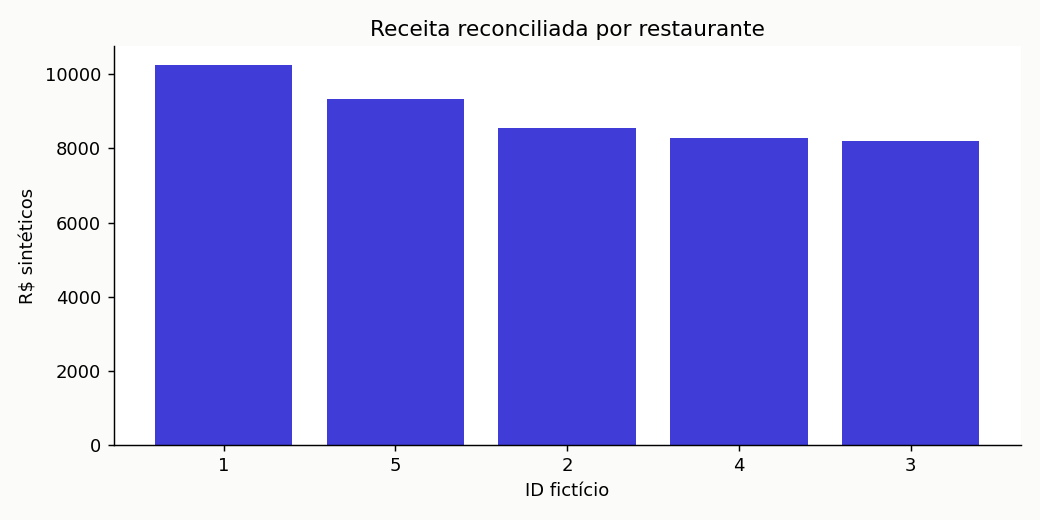

In [6]:
for name in ['04_monthly.sql','05_item_margin.sql','06_ticket.sql']:
    print(name)
    display(query(con,name))
display(Image(filename=str(outdir()/'revenue.png')))
con.close()

## Caso manual

Dois itens a 1000 centavos geram 2000 centavos de receita; custo300 por unidade dá contribuição1400. Esse caso está no teste19. Os testes também provocam falhas, duplicatas e rollback. PostgreSQL foi validado à parte por `python -m src.verify_postgres`.

In [7]:
quantity, price, cost = 2, 1000, 300
assert quantity*price == 2000
assert quantity*(price-cost) == 1400
print('Conferência manual OK')

Conferência manual OK


## Verificações e reprodução

Execute `python -m unittest discover -s tests -v` na raiz. Os requisitos de notebook são separados dos requisitos mínimos do pipeline. A saída deste arquivo é de execução local real; isso não significa que já rodou no Dell, no GitHub ou em produção. Consulte os créditos e as limitações antes de publicar.